# MNIST exploration

Loads MNIST, checks shapes and class balance, shows sample digits, and looks at how much variance PCA keeps.

In [1]:
import sys
from pathlib import Path

# Make `src` importable when the notebook runs from notebooks/
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

from src.data import load_mnist

X_train, X_test, y_train, y_test = load_mnist()
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Pixel range: {X_train.min():.1f} to {X_train.max():.1f}")

Loading MNIST...


OpenML unavailable (URLError); using mnist.npz mirror.


X_train: (60000, 784), X_test: (10000, 784)
Pixel range: 0.0 to 1.0


In [2]:
counts = np.bincount(y_train)
for digit, n in enumerate(counts):
    print(f"{digit}: {n:>5} ({n / len(y_train):.1%})")

0:  5923 (9.9%)
1:  6742 (11.2%)
2:  5958 (9.9%)
3:  6131 (10.2%)
4:  5842 (9.7%)
5:  5421 (9.0%)
6:  5918 (9.9%)
7:  6265 (10.4%)
8:  5851 (9.8%)
9:  5949 (9.9%)


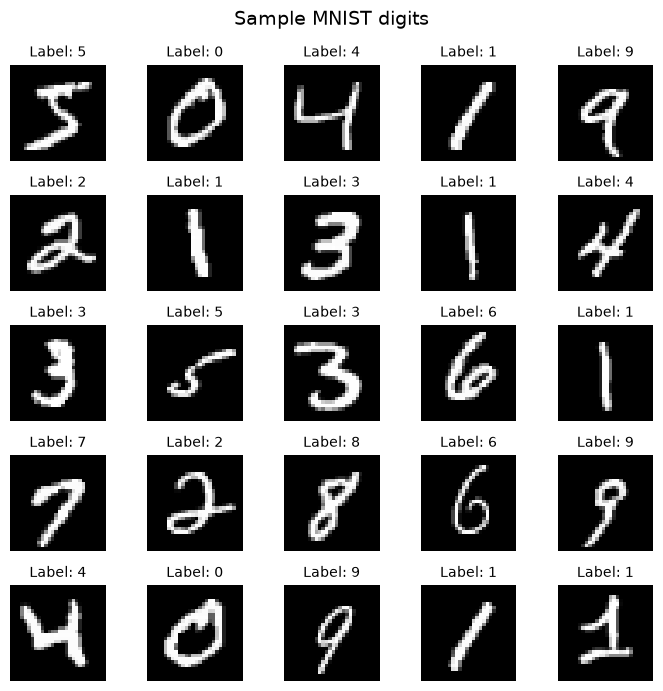

In [3]:
fig, axes = plt.subplots(5, 5, figsize=(7, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
    ax.set_title(f"Label: {y_train[i]}", fontsize=10)
fig.suptitle("Sample MNIST digits", fontsize=14)
fig.tight_layout()
plt.show()

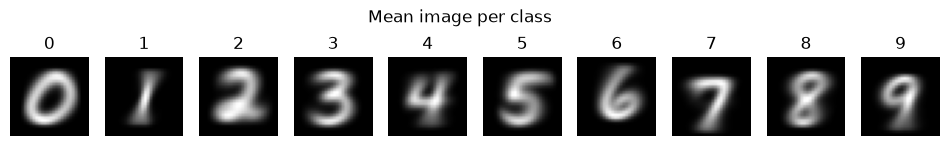

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for digit, ax in enumerate(axes):
    ax.imshow(X_train[y_train == digit].mean(axis=0).reshape(28, 28), cmap="gray")
    ax.set_title(str(digit))
    ax.axis("off")
fig.suptitle("Mean image per class")
plt.show()

In [5]:
cumsum = np.cumsum(PCA(random_state=42).fit(X_train).explained_variance_ratio_)
for k in (10, 50, 100, 154):
    print(f"{k:>3} components: {cumsum[k - 1]:.1%} of variance")

 10 components: 48.8% of variance
 50 components: 82.5% of variance
100 components: 91.5% of variance
154 components: 95.0% of variance
